# WESAD ACC Signal Inspection

This notebook inspects the Accelerometer (ACC) signals from the WESAD dataset to determine the level of movement (stillness vs. fidgeting vs. active movement) during different session phases. 

We specifically focus on the **Wrist (Empatica E4)** data as it's most relevant to hand movement assessment in a controlled lab condition.

In [7]:
import os
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [15, 6]

In [8]:
# Find WESAD directory
cwd = Path.cwd()
repo_root = next(p for p in [cwd, *cwd.parents] if (p / 'WESAD').exists())
wesad_dir = repo_root / 'WESAD'
subject = 'S13'
subject_path = wesad_dir / subject / f'{subject}.pkl'

print(f"Loading data for {subject} from: {subject_path}")

with open(subject_path, 'rb') as f:
    data = pickle.load(f, encoding='latin1')

print(f"Keys in data: {data.keys()}")

Loading data for S13 from: e:\Rizqy\Kuliah\Skripsi\repo-skripsi\WESAD\S13\S13.pkl
Keys in data: dict_keys(['signal', 'label', 'subject'])


In [9]:
# Extract Wrist ACC and Labels
# E4 ACC sampling rate is 32Hz
# Labels sampling rate matches Chest (RespiBan) which is 700Hz

acc_wrist = data['signal']['wrist']['ACC']
labels = data['label']

print(f"Wrist ACC shape: {acc_wrist.shape}")
print(f"Labels shape: {labels.shape}")

# Note: The labels are sampled at 700Hz, while E4 ACC is at 32Hz.
# We need to align them for precise phase analysis if needed, 
# but for a general look at movement, we can just look at the ACC signals.

Wrist ACC shape: (177184, 3)
Labels shape: (3875900,)


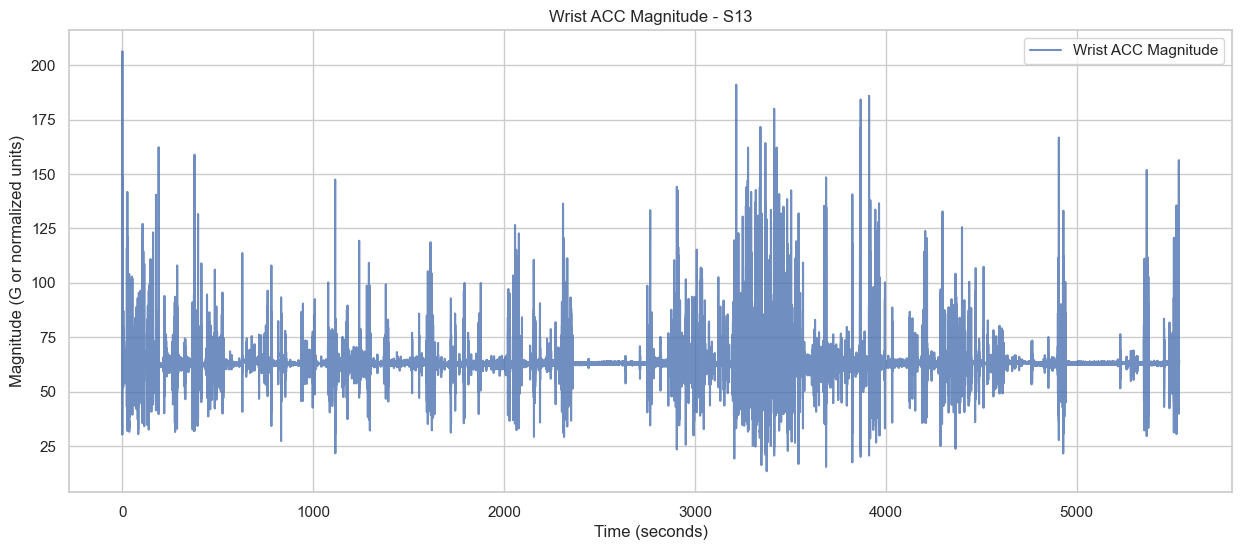

In [10]:
# Calculate ACC Magnitude (Resultant Vector)
mag_wrist = np.sqrt(np.sum(np.square(acc_wrist), axis=1))

# Create a time axis for 32Hz signal
time_wrist = np.arange(len(mag_wrist)) / 32.0

plt.figure()
plt.plot(time_wrist, mag_wrist, label='Wrist ACC Magnitude', alpha=0.8)
plt.title(f"Wrist ACC Magnitude - {subject}")
plt.xlabel("Time (seconds)")
plt.ylabel("Magnitude (G or normalized units)")
plt.legend()
plt.show()

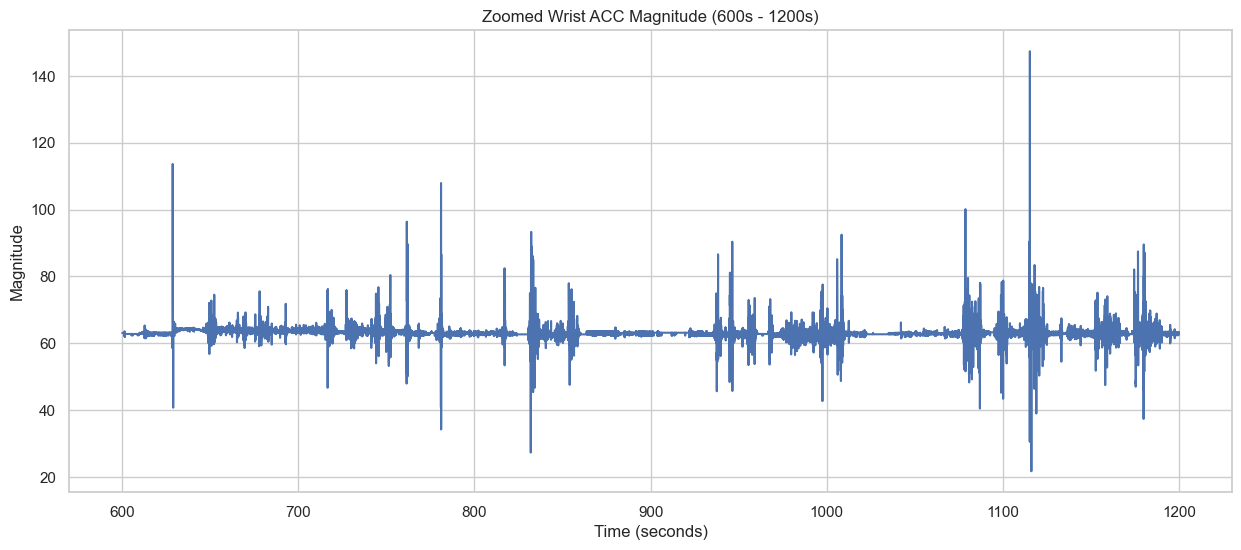

Standard Deviation in this window: 2.5296
Peak-to-Peak in this window: 125.7179


In [11]:
# Let's zoom into a few minutes of data to see 'stillness' vs 'fidgeting'
start_sec = 600
end_sec = 1200

mask = (time_wrist >= start_sec) & (time_wrist <= end_sec)

plt.figure()
plt.plot(time_wrist[mask], mag_wrist[mask])
plt.title(f"Zoomed Wrist ACC Magnitude ({start_sec}s - {end_sec}s)")
plt.xlabel("Time (seconds)")
plt.ylabel("Magnitude")
plt.show()

print(f"Standard Deviation in this window: {np.std(mag_wrist[mask]):.4f}")
print(f"Peak-to-Peak in this window: {np.ptp(mag_wrist[mask]):.4f}")

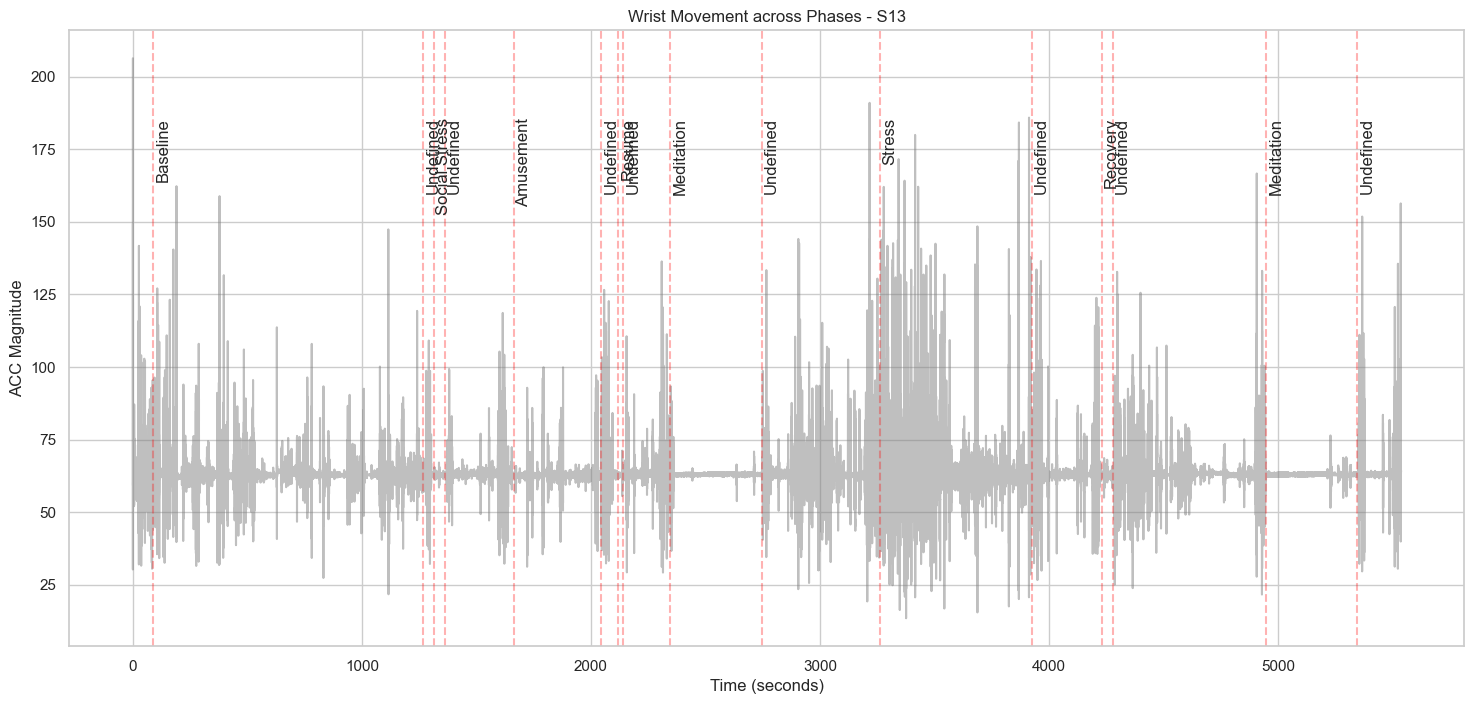

In [12]:
# Align labels (700Hz) to ACC (32Hz) roughly by resampling or nearest neighbor
# For visualization, we can just overlay the label transitions

label_map = {
    0: 'Undefined',
    1: 'Baseline',
    2: 'Stress',
    3: 'Amusement',
    4: 'Meditation',
    5: 'Social Stress',
    6: 'Recovery',
    7: 'Resume'
}

# Find label changes in the 700Hz signal
label_changes = np.where(labels[:-1] != labels[1:])[0]
change_times = label_changes / 700.0

plt.figure(figsize=(18, 8))
plt.plot(time_wrist, mag_wrist, color='gray', alpha=0.5, label='ACC Magnitude')

for i, t in enumerate(change_times):
    plt.axvline(x=t, color='red', linestyle='--', alpha=0.3)
    l_idx = label_changes[i] + 1
    label_name = label_map.get(labels[l_idx], 'Unknown')
    plt.text(t + 10, np.max(mag_wrist)*0.9, label_name, rotation=90, verticalalignment='top')

plt.title(f"Wrist Movement across Phases - {subject}")
plt.xlabel("Time (seconds)")
plt.ylabel("ACC Magnitude")
plt.show()

### Conclusion for Participant {subject}

Based on the magnitude and variance of the ACC signal:
- **Stillness**: Represented by very low variance and magnitude close to gravity (usually ~64 for E4 if not normalized, or ~1G).
- **Fidgeting**: Small spikes and increased variance, but no large baseline shifts.
- **Movement**: Large spikes and shifts in the magnitude vector.

In WESAD, participants are generally sitting, but their hand activity varies by phase (e.g., amusement might involve laughter/movement, while meditation should be still).